## Deep Neural Network with Hidden Layers

In [65]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

from utils import SIZE, CLASSES, prepare_data_set, plot_costs, load_image, get_label
from checks import check_l2_cost
from dnn import (
    relu, sigmoid, initialize_parameters, activate,
    ActivationCache, PropagateCache, ForwardCache,
    propagate, propagate_backward,
    AL_derivative, relu_backward, sigmoid_backward,
)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [66]:
datasets = prepare_data_set()

Y_train = datasets["Y_train"]
X_train = datasets ["X_train"]
X_test = datasets["X_test"]
Y_test = datasets["Y_test"]
X_test_orig_set = datasets["X_test_orig_set"]
X_train_orig_set = datasets["X_train_orig_set"]


In [67]:
def forward_pass(X, parameters):
    # find the number of layers from the initialized parameters
    L = len(parameters) // 2

    # print(f"Len Layer: {L}")
    cache = [] # we need this later for backward propagation
    Aprev = X # initial assignment to A0
    for l in range(0,L):
        # here we calculate Zl     
        Zl, pc = propagate(parameters["W"+str(l+1)], Aprev, parameters["b"+str(l+1)])
        # here we calculate Al (it should be started from 1 by the loop)
        if (l == (L-1)): # for output layer, we use sigmoid
            Aprev, ac= activate(Zl, "sigmoid")
        else:
            Aprev, ac= activate(Zl, "relu")
        forward_cache = ForwardCache(PropagateCache = pc, ActivationCache=ac) 
        cache.append(forward_cache)
    output = Aprev
    # print(f"Len in forward: {len(cache)} {len(parameters)} ")
    return output, cache

In [73]:
def backward_pass(AL, Y, caches):

    grads = {}
    L = len(caches)
    current_layer_cache = caches[L-1]
    current_layer_W = current_layer_cache.PropagateCache.W
    current_layer_Aprev = current_layer_cache.PropagateCache.Aprev
    
    # calculate the dAL
    dAL = AL_derivative(AL, Y)

    # get the dZ for outer/output layer
    dZ = sigmoid_backward(dAL, current_layer_cache.ActivationCache)
    dW,db, dAprev = propagate_backward(dZ, current_layer_Aprev, current_layer_W )
    grads["dW"+str(L)] = dW
    grads["db"+str(L)] = db

    # print(f"l in backward = {L}")
    
    for l in reversed (range (L-1)):
        current_layer_cache = caches[l]
        current_layer_W = current_layer_cache.PropagateCache.W
        current_layer_Aprev = current_layer_cache.PropagateCache.Aprev
        dZ = relu_backward(dAprev, current_layer_cache.ActivationCache)
        dW,db,dAprev = propagate_backward(dZ, current_layer_Aprev, current_layer_W)
        # print(f"l in backward = {l+1}")
        grads["dW" + str(l+1)] = dW
        grads["db" + str(l+1)] = db
    

    # print(f"grads: {len(grads)}")

    # for l in range (1, L+1):
    #     print(f"grads: {grads["dW" + str(l)].shape}")
    
    return grads
    

In [74]:
def calculate_cost(AL,Y):
    m = AL.shape[1]
    cost =  -(1./m) * np.sum((np.dot(Y,np.log(AL).T) + np.dot(1-Y, np.log(1-AL).T)))
    # make sure the output not a 0-dimensional array/scalar
    # eg 2D array (matrix) number: [[24]] => become 24.
    res = np.squeeze(cost)
    return res

In [75]:
def update_parameter(parameters, grads, learning_rate):

    # floor divide by 2 because each layer has both a 'W' and a 'b'
    L = len(parameters) // 2
    
    for l in range (0, L):
        parameters["W" + str(l+1)] = parameters["W" + str(l+1)] - (learning_rate * grads["dW"+str(l+1)])
        parameters["b" + str(l+1)] = parameters["b" + str(l+1)] - (learning_rate * grads["db"+str(l+1)])

    assert len(grads) == len(parameters)
    return parameters

In [90]:
# classify will apply the propagation with the given parameters
# and return the classification as 1 or 0
def classify(X,parameters):
    output, _ = forward_pass(X,parameters)
    return (output > 0.5).astype(int)


def dnn_model(X_train, Y_train, X_test, Y_test, layers_dims, iteration=2500, learning_rate=0.0075, print_cost=False):
    parameters = initialize_parameters(layers_dims)
    costs = []
    for i in range(1,iteration+1):
        AL, cache = forward_pass(X_train, parameters)
        cost = calculate_cost(AL,Y_train)
        grads = backward_pass(AL, Y_train, cache)
        parameters = update_parameter(parameters, grads, learning_rate)
        # print(f"Cost: {cost}")
        costs.append(cost)
        if (i%100 == 0) and print_cost:
            print(f"Cost: {cost}")
            

    Y_prediction_train = classify(X_train, parameters)
    Y_prediction_test  = classify(X_test, parameters)

    train_acc = 100 - np.mean(np.abs(Y_prediction_train - Y_train)) * 100
    test_acc = 100 - np.mean(np.abs(Y_prediction_test - Y_test)) * 100
    print(f"train_accuracy: {train_acc}%")
    print(f"test_accuracy: {test_acc}%")

    return parameters, costs
    

In [93]:
# Full-batch gradient descent: every update uses all training examples, so one
# iteration is one epoch and `costs` has exactly one point per epoch.
# Compare with the per-mini-batch plot in minibatches.ipynb: this line is smooth.
def plot_epoch_costs(costs, label, learning_rate):
    plt.plot(np.arange(1, len(costs) + 1), costs)
    plt.xlabel("epoch (1 full-batch update each)")
    plt.ylabel("cost")
    plt.title(f"{label}; learning rate = {learning_rate}")
    plt.show()

In [91]:
import time 
start_time = time.perf_counter()
input_features= X_train.shape[0]
iteration = 2500
learning_rate = 0.0075

layer_dims_deep = [input_features, 30, 20, 10, 1]
parameter_deep, cost_deep = dnn_model(
        X_train=X_train, 
        Y_train=Y_train, 
        X_test=X_test, 
        Y_test=Y_test, 
        layers_dims=layer_dims_deep, 
        iteration=iteration, 
        learning_rate=learning_rate,
        print_cost=True)

end_time = time.perf_counter()
elapsed_seconds = end_time - start_time
# Divide by 60 to get minutes
elapsed_minutes = elapsed_seconds / 60
print(f"Execution time: {elapsed_minutes:.2f} minutes")

Cost: 0.6706123996189951
Cost: 0.6544906006184986
Cost: 0.6441715479051585
Cost: 0.6384387879833883
Cost: 0.6341812897657949
Cost: 0.6300031539380037
Cost: 0.6258333056628433
Cost: 0.6250146973855221
Cost: 0.6197278745280302
Cost: 0.6159734172331458
Cost: 0.6134135470041084
Cost: 0.6106369752601296
Cost: 0.607953276740414
Cost: 0.6054405832097858
Cost: 0.6018531745994209
Cost: 0.6006432448869331
Cost: 0.5940471340718035
Cost: 0.5914483475838979
Cost: 0.5902119582835486
Cost: 0.5854617727897983
Cost: 0.5817429680559649
Cost: 0.5806575322448108
Cost: 0.5789169473712463
Cost: 0.5734115814685562
Cost: 0.5718193505556854
train_accuracy: 70.59337913803873%
test_accuracy: 62.77805239742956%
Execution time: 13.59 minutes


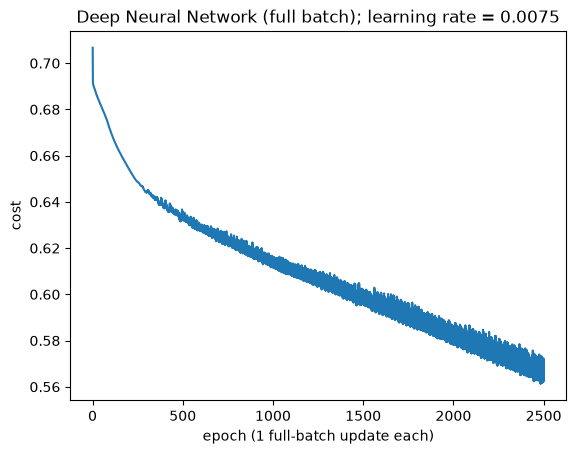

In [94]:
plot_epoch_costs(cost_deep, "Deep Neural Network (full batch)", learning_rate)

In [188]:
layer_dims_deep = [input_features, 30, 1]

parameter_shallow, cost_shallow = dnn_model(X_train, Y_train, X_test, Y_test, layer_dims_deep, iteration, learning_rate, print_cost=True)

Cost: 0.6664566905153884
Cost: 0.653754439300079
Cost: 0.6454216908224192
Cost: 0.6393151703905681
Cost: 0.6333592564225535
Cost: 0.628276828207738
Cost: 0.6238465716630179
Cost: 0.6200319204531786
Cost: 0.6162629389172097
Cost: 0.6134318920052672
Cost: 0.6101133059045745
Cost: 0.6067536418810093
Cost: 0.6041455090667792
Cost: 0.6005811227350999
Cost: 0.5967552792877797
Cost: 0.5943910831612486
Cost: 0.590881270417842
Cost: 0.5888594094527492
Cost: 0.5869722277177416
Cost: 0.5836998092375439
Cost: 0.5805272723539959
Cost: 0.5781581872456758
Cost: 0.5756288538808784
Cost: 0.5728286913575238
Cost: 0.5698092237852936
train_accuracy: 68.84447220487195%
test_accuracy: 63.173504695996044%


In [ ]:
plot_epoch_costs(cost_shallow, "Shallow Neural Network (full batch)", learning_rate)

In [192]:
layer_dims_deep = [input_features, 1]

parameter_logistic_regression, cost_logistic_regression = dnn_model(X_train, Y_train, X_test, Y_test, layer_dims_deep, iteration, learning_rate, print_cost=True)

Cost: 2.2926639818992256
Cost: 2.173352140493441
Cost: 2.104987579385317
Cost: 2.057349855937839
Cost: 2.021686485394459
Cost: 1.9936647206468106
Cost: 1.9709029116885257
Cost: 1.9519543036301077
Cost: 1.9358605182213058
Cost: 1.9219480081588218
Cost: 1.9097275684543293
Cost: 1.8988372303876195
Cost: 1.8890055692918002
Cost: 1.880026616572469
Cost: 1.8717422618900326
Cost: 1.8640297558816512
Cost: 1.8567927577855308
Cost: 1.8499548706118571
Cost: 1.8434549330202592
Cost: 1.837243558602249
Cost: 1.8312805659010256
Cost: 1.825533048515677
Cost: 1.8199739085736188
Cost: 1.8145807285020996
Cost: 1.8093348921274188
train_accuracy: 52.91692692067458%
test_accuracy: 53.583786455758776%


In [ ]:
plot_epoch_costs(cost_logistic_regression, "Logistic Regression (full batch)", learning_rate)

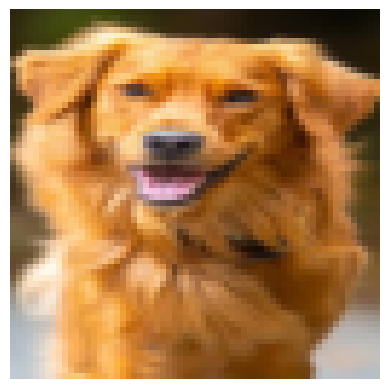

In [233]:
my_image = "cute_dog.jpeg"
image, x_real_data = load_image(my_image)

plt.imshow(image)
plt.axis("off")

Deep Neural Network predict it's a dogs picture


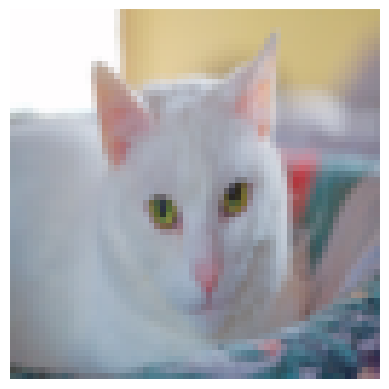

In [60]:
my_image = "catbig.jpg"
image, x_real_data = load_image(my_image)

plt.imshow(image)
plt.axis("off")



# logistic_prediction = classify(x_real_data, parameter_logistic_regression)
# print(f"Logistic Regression predict it's a {get_label(logistic_prediction)} picture")


# shallow_prediction = classify(x_real_data, parameter_shallow)
# print(f"Shallow Neural Network predict it's a {get_label(shallow_prediction)} picture")


deep_prediction = classify(x_real_data, parameter_deep)
print(f"Deep Neural Network predict it's a {get_label(deep_prediction)} picture")